# El Niño 3.4 e chuva em São Paulo — volume e intensidade

## A hipótese, em quatro elos

```text
[1] o Pacífico esquenta (projeção do nooa.ipynb, agora até JFM/2027)
        ↓
[2] chove mais no mês, em cada zona de São Paulo
        ↓
[3] chove mais forte, e não só mais vezes
        ↓
[4] chuva forte em pouco tempo é o que alaga
```

Este notebook mede **os elos 2 e 3**. O elo 4 não se mede aqui: depende de
drenagem, relevo e impermeabilização de cada rua.

## O que já se sabia e o que falta

- O elo 2 já tinha número: **+5,8 mm por °C** no acumulado do mês.
- Mas mm/mês não diz nada sobre pancada. Um mês com 12 mm a mais pode
  chover mais vezes fraco, ou chover a mesma coisa em uma tempestade só.
- Alagamento responde à **intensidade**, não ao total.

## Dados

| Base | Resolução | Período | Papel |
|---|---|---|---|
| `df_hist_roni` (banco) | mensal | 1950–2026 | preditor: anomalia NINO3.4 (média móvel de 3 meses) |
| ERA5-Land diário (Open-Meteo) | 0,1° (~11 km) | 1961–2026 | total do mês, maior dia, dias acima de 25 e 50 mm |
| ERA5 horário (Open-Meteo) | 0,25° (~28 km) | 1961–2026 | maior hora, p99 da hora, horas acima de 20 mm |
| `df_2026` (banco) | trimestral | 2026–2027 | projeção do NINO3.4 para jan e fev de 2027 |

## Método

1. Chuva diária -> soma mensal e indicadores de intensidade por zona.
2. Anomalia = chuva do mês menos a climatologia do mesmo mês (1991–2020).
3. Correlação entre anomalia e NINO3.4, com defasagem de 0 a 12 meses.
4. Regressão com efeito fixo de mês e de zona (`statsmodels`, erro agrupado por ano).
5. O mesmo modelo para cada métrica de intensidade, comparando o efeito
   em **% da média** — é assim que se vê se a pancada cresce mais que o total.
6. Bootstrap por ano para testar se a diferença entre os dois efeitos é real.
7. Cenário: aplicar os coeficientes à projeção DJF/JFM de 2027.

## Limites que valem para tudo abaixo

- ERA5 é reanálise, não pluviômetro. O diário é grade de ~11 km; o horário,
  de ~28 km. Não serve para dizer a chuva de uma rua.
- O ERA5 horário não distingue Centro, Norte e Oeste antes de 2017: as três
  caem na mesma célula de 0,25°. Só Leste e Sul têm célula própria o tempo todo.
- A série horária muda de fonte em 2017 (a grade passa a ser mais fina).
  Os efeitos calculados só com 2017–2026 são maiores, mas com 117 meses e
  dois El Niños fortes no meio; trato 1961–2016 como o resultado principal.
- NINO3.4 é média móvel de 3 meses: meses vizinhos são autocorrelacionados,
  e as correlações trazem o n efetivo corrigido.
- Correlação não prova causalidade.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

RAIZ = Path("..").resolve()
DADOS = RAIZ / "Notebookes" / "dados"
SAIDAS = RAIZ / "Notebookes" / "saidas"
DADOS.mkdir(exist_ok=True)
SAIDAS.mkdir(exist_ok=True)

CACHE_DIARIO = DADOS / "era5_zonas_diario.csv"
CACHE_HORARIO = DADOS / "era5_zonas_horario_mensal.csv"
INICIO = "1961-01-01"
FIM = "2026-10-31"
BASE_CLIMA = (1991, 2020)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 180)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

print(f"Raiz: {RAIZ}")
for arquivo in (CACHE_DIARIO, CACHE_HORARIO):
    estado = "ok" if arquivo.exists() else "AUSENTE"
    print(f"  {arquivo.name:<32} {estado}")

Raiz: C:\TI\Projetos Univesp\projeto-climaSP
  era5_zonas_diario.csv            ok
  era5_zonas_horario_mensal.csv    ok


## 1. Chuva diaria

ERA5-Land em cache local. Se o arquivo nao existir, baixa de novo.

In [2]:
def baixar_serie(lat, lon, passo, bloco=None):
    """Baixa uma serie do Open-Meteo Archive e devolve Series indexada por data."""
    url = (
        f"https://archive-api.open-meteo.com/v1/archive?latitude={lat}&longitude={lon}"
        f"&start_date={bloco[0] if bloco else INICIO}"
        f"&end_date={bloco[1] if bloco else FIM}"
        f"&{passo}=precipitation&timezone=America%2FSao_Paulo"
    )
    for tentativa in range(1, 5):
        try:
            import json, time, urllib.error, urllib.request
            with urllib.request.urlopen(url, timeout=300) as resposta:
                local = json.load(resposta)
            chave = "hourly" if passo == "hourly" else "daily"
            return pd.Series(
                local[chave]["precipitation"],
                index=pd.to_datetime(local[chave]["time"]),
                dtype="float64",
            )
        except urllib.error.HTTPError as erro:
            if erro.code != 429:
                raise
            time.sleep(20 * tentativa)
    raise RuntimeError(f"Open-Meteo recusou {lat}/{lon}.")


def pontos_das_zonas():
    import geopandas as gpd

    zonas = gpd.read_file(RAIZ / "zonas_sp.geojson").to_crs(4326)
    return {
        linha["zona"]: (
            round(linha.geometry.representative_point().y, 4),
            round(linha.geometry.representative_point().x, 4),
        )
        for _, linha in zonas.iterrows()
    }


if CACHE_DIARIO.exists():
    chuva_diaria = pd.read_csv(
        CACHE_DIARIO, sep=";", encoding="utf-8-sig", decimal=",", parse_dates=["data"]
    )
    print(f"Cache diario carregado: {len(chuva_diaria):,} linhas")
else:
    import json, time  # noqa: F401  (usados dentro de baixar_serie)

    partes = []
    for i, (zona, (lat, lon)) in enumerate(pontos_das_zonas().items()):
        if i:
            time.sleep(8)
        serie = baixar_serie(lat, lon, "daily")
        if serie.isna().any() or serie.sum() == 0:
            raise RuntimeError(f"Resposta invalida para {zona}.")
        partes.append(pd.DataFrame({"zona": zona, "data": serie.index, "chuva_mm": serie.values}))
    chuva_diaria = pd.concat(partes, ignore_index=True)
    chuva_diaria.to_csv(CACHE_DIARIO, index=False, encoding="utf-8-sig", sep=";", decimal=",")
    print(f"Baixado: {len(chuva_diaria):,} linhas")

print(chuva_diaria.groupby("zona")["data"].agg(["min", "max", "size"]).to_string())

Cache diario carregado: 120,225 linhas
              min        max   size
zona                               
Centro 1961-01-01 2026-10-31  24045
Leste  1961-01-01 2026-10-31  24045
Norte  1961-01-01 2026-10-31  24045
Oeste  1961-01-01 2026-10-31  24045
Sul    1961-01-01 2026-10-31  24045


## 2. Chuva horaria

Indicadores de pancada. O download e longo, por isso o cache e obrigatorio.

In [3]:
BLOCOS = [
    ("1961-01-01", "1970-12-31"), ("1971-01-01", "1980-12-31"),
    ("1981-01-01", "1990-12-31"), ("1991-01-01", "2000-12-31"),
    ("2001-01-01", "2010-12-31"), ("2011-01-01", "2020-12-31"),
    ("2021-01-01", FIM),
]


def resumir_mes(horas):
    """Indicadores de intensidade de um mes a partir da serie horaria."""
    total = float(horas.sum())
    ordenado = np.sort(horas.to_numpy())
    topo = max(int(round(len(ordenado) * 0.01)), 1)
    return {
        "chuva_horaria_mm": total,
        "max_1h_mm": float(horas.max()),
        "p95_hora_mm": float(np.percentile(ordenado, 95)),
        "p99_hora_mm": float(np.percentile(ordenado, 99)),
        "horas_ge_10": int((horas >= 10).sum()),
        "horas_ge_20": int((horas >= 20).sum()),
        "concentracao_topo1pct": float(ordenado[-topo:].sum() / total) if total > 0 else np.nan,
    }


if CACHE_HORARIO.exists():
    chuva_horaria = pd.read_csv(
        CACHE_HORARIO, sep=";", encoding="utf-8-sig", decimal=",", parse_dates=["mes"]
    )
    print(f"Cache horario carregado: {len(chuva_horaria):,} linhas")
else:
    # ~35 requisicoes, cerca de 10 minutos. Rode uma vez e o cache fica salvo.
    import time

    print("Cache ausente: baixando a serie horaria (10 min)...")
    linhas = []
    for zona, (lat, lon) in pontos_das_zonas().items():
        for inicio, fim in BLOCOS:
            serie = baixar_serie(lat, lon, "hourly", bloco=(inicio, fim))
            if serie.isna().any():
                raise RuntimeError(f"{zona} {inicio}: horas nulas.")
            for mes, horas in serie.groupby(serie.index.to_period("M")):
                linhas.append({"zona": zona, "mes": mes.start_time, **resumir_mes(horas)})
            time.sleep(6)
        print(f"  {zona} ok")

    chuva_horaria = pd.DataFrame(linhas).sort_values(["zona", "mes"]).reset_index(drop=True)
    chuva_horaria.to_csv(CACHE_HORARIO, index=False, encoding="utf-8-sig", sep=";", decimal=",")
    print(f"Baixado: {len(chuva_horaria):,} linhas")

print(chuva_horaria.groupby("zona")["mes"].agg(["min", "max", "size"]).to_string())

Cache horario carregado: 3,950 linhas
              min        max  size
zona                              
Centro 1961-01-01 2026-10-01   790
Leste  1961-01-01 2026-10-01   790
Norte  1961-01-01 2026-10-01   790
Oeste  1961-01-01 2026-10-01   790
Sul    1961-01-01 2026-10-01   790


In [4]:
chuva_diaria["mes"] = chuva_diaria["data"].dt.to_period("M").dt.start_time

chuva_mensal = (
    chuva_diaria.groupby(["zona", "mes"], as_index=False)
    .agg(
        chuva_mm=("chuva_mm", "sum"),
        dias=("chuva_mm", "size"),
        dias_com_chuva=("chuva_mm", lambda s: int((s >= 1).sum())),
        max_dia_mm=("chuva_mm", "max"),
        dias_ge_10=("chuva_mm", lambda s: int((s >= 10).sum())),
        dias_ge_25=("chuva_mm", lambda s: int((s >= 25).sum())),
        dias_ge_50=("chuva_mm", lambda s: int((s >= 50).sum())),
    )
)

intensidade = chuva_mensal.merge(
    chuva_horaria.drop(columns="chuva_mm"),
    on=["zona", "mes"],
    how="left",
    validate="one_to_one",
)

if intensidade["max_1h_mm"].isna().any():
    raise ValueError("Mes sem serie horaria: os dois caches nao cobrem o mesmo periodo.")

print(f"{len(intensidade):,} linhas | {intensidade['zona'].nunique()} zonas | "
      f"{intensidade['mes'].min():%Y-%m} a {intensidade['mes'].max():%Y-%m}")

anual = chuva_mensal.groupby(["zona", chuva_mensal["mes"].dt.year])["chuva_mm"].sum().unstack(0)
print("\nChuva anual (mm):")
print(anual.agg(["mean", "std"]).round(0).to_string())
print("\nMedia mensal das metricas de intensidade:")
print(intensidade.groupby("zona")[
    ["chuva_mm", "max_dia_mm", "max_1h_mm", "p99_hora_mm", "dias_ge_25", "dias_ge_50"]
].mean().round(2).to_string())

3,950 linhas | 5 zonas | 1961-01 a 2026-10

Chuva anual (mm):
zona  Centro   Leste   Norte   Oeste     Sul
mean  1327.0  1412.0  1334.0  1331.0  1723.0
std    215.0   227.0   210.0   213.0   327.0

Media mensal das metricas de intensidade:
        chuva_mm  max_dia_mm  max_1h_mm  p99_hora_mm  dias_ge_25  dias_ge_50
zona                                                                        
Centro    110.87       24.30       6.41         2.57        0.62        0.07
Leste     117.93       25.31       6.49         2.68        0.67        0.08
Norte     111.49       24.34       6.44         2.59        0.62        0.07
Oeste     111.17       24.29       6.37         2.58        0.62        0.08
Sul       143.92       28.81       7.38         3.09        0.96        0.10


## 3. ENSO

`df_hist_roni`: anomalia NINO3.4, media movel de 3 meses, 1950-2026.

In [5]:
from sqlalchemy import create_engine, text
import os

for linha in (RAIZ / "Notebookes" / ".env").read_text(encoding="utf-8").splitlines():
    if "=" in linha and not linha.lstrip().startswith("#"):
        chave, valor = linha.split("=", 1)
        os.environ[chave.strip()] = valor.strip().strip('"').strip("'")

engine = create_engine(os.environ["SUPABASE_DB_URL"], connect_args={"connect_timeout": 15})

enso_bruto = pd.read_sql(text('SELECT * FROM "df_hist_roni"'), engine)
enso = (
    enso_bruto.assign(mes=pd.to_datetime(enso_bruto["data"]))
    .rename(columns={"ANOM": "nino34"})[["mes", "SEAS", "nino34"]]
    .sort_values("mes")
    .reset_index(drop=True)
)

print(f"ENSO: {len(enso):,} meses | {enso['mes'].min():%Y-%m} a {enso['mes'].max():%Y-%m}")
print(f"nino34: min {enso['nino34'].min():.2f} | max {enso['nino34'].max():.2f} "
      f"| nulos {int(enso['nino34'].isna().sum())}")

projecao = pd.read_sql(text('SELECT * FROM "df_2026"'), engine)
print("\nProjecao vinda do nooa.ipynb (df_2026):")
print(projecao[projecao["Origem"] == "Previsto"].to_string(index=False))

ENSO: 921 meses | 1950-01 a 2026-09
nino34: min -1.95 | max 2.40 | nulos 0

Projecao vinda do nooa.ipynb (df_2026):
 index Temporada  NINO34_MM3    Fase  Ano   Origem
     9       SON       2.313 El Niño 2026 Previsto
    10       OND       2.445 El Niño 2026 Previsto
    11       NDJ       2.448 El Niño 2026 Previsto
    12       DJF       2.314 El Niño 2027 Previsto
    13       JFM       1.982 El Niño 2027 Previsto


## 4. Painel e climatologia

In [6]:
painel = intensidade.merge(enso[["mes", "nino34"]], on="mes", how="inner")
painel["ano"] = painel["mes"].dt.year
painel["mes_num"] = painel["mes"].dt.month

print(f"Painel: {len(painel):,} linhas | {painel['ano'].min()}-{painel['ano'].max()}")

base = painel[painel["ano"].between(*BASE_CLIMA)]
METRICAS = ["chuva_mm", "max_dia_mm", "max_1h_mm", "p99_hora_mm", "dias_ge_25", "dias_ge_50"]

clima = (
    base.groupby(["zona", "mes_num"])[METRICAS]
    .mean()
    .rename(columns={m: f"clima_{m}" for m in METRICAS})
    .reset_index()
)

painel = painel.merge(clima, on=["zona", "mes_num"], how="left")
painel["anomalia_mm"] = painel["chuva_mm"] - painel["clima_chuva_mm"]
painel["anomalia_pct"] = painel["anomalia_mm"] / painel["clima_chuva_mm"] * 100

print("\nClimatologia 1991-2020 do total (mm):")
print(clima.pivot(index="mes_num", columns="zona", values="clima_chuva_mm").round(0).to_string())

Painel: 3,945 linhas | 1961-2026

Climatologia 1991-2020 do total (mm):
zona     Centro  Leste  Norte  Oeste    Sul
mes_num                                    
1         229.0  236.0  229.0  228.0  278.0
2         167.0  186.0  169.0  167.0  234.0
3         139.0  155.0  139.0  139.0  209.0
4          60.0   64.0   61.0   60.0   93.0
5          59.0   64.0   60.0   59.0   75.0
6          45.0   47.0   44.0   44.0   59.0
7          50.0   55.0   50.0   50.0   67.0
8          35.0   38.0   35.0   35.0   50.0
9          83.0   89.0   84.0   84.0  106.0
10        110.0  114.0  110.0  110.0  133.0
11        143.0  150.0  147.0  144.0  179.0
12        167.0  179.0  170.0  169.0  215.0


## 5. Correlacao com defasagem

Defasagem k significa: chuva de hoje contra NINO3.4 de k meses atras.

In [7]:
from scipy.stats import pearsonr


def correlacao_por_defasagem(painel, max_lag=12):
    linhas = []
    for zona, serie in painel.groupby("zona"):
        serie = serie.set_index("mes")
        for lag in range(max_lag + 1):
            # chuva de t contra NINO3.4 de t-lag
            nino = enso.assign(mes=enso["mes"] + pd.DateOffset(months=lag))[["mes", "nino34"]]
            par = serie[["anomalia_mm"]].join(nino.set_index("mes"), how="inner").dropna()
            if len(par) < 60:
                continue
            r, p = pearsonr(par["anomalia_mm"], par["nino34"])
            linhas.append({"zona": zona, "lag_meses": lag, "r": r, "p": p, "n": len(par)})
    return pd.DataFrame(linhas)


def r_efetivo(par):
    """Corrige o n pela autocorrelacao das duas series (Bartlett)."""
    r1x = par["anomalia_mm"].autocorr(1)
    r1y = par["nino34"].autocorr(1)
    fator = (1 - r1x * r1y) / (1 + r1x * r1y)
    n_ef = max(int(len(par) * fator), 10)
    r, _ = pearsonr(par["anomalia_mm"], par["nino34"])
    from scipy.stats import t as t_dist
    t = r * np.sqrt((n_ef - 2) / max(1 - r**2, 1e-12))
    return {"r": r, "n": len(par), "n_efetivo": n_ef,
            "p_efetivo": 2 * (1 - t_dist.cdf(abs(t), n_ef - 2))}


correlacoes = correlacao_por_defasagem(painel)

print("Correlacao anomalia de chuva x NINO3.4 (r) por defasagem:")
print(correlacoes.pivot(index="lag_meses", columns="zona", values="r").round(3).to_string())

resumo_lag = []
for zona, serie in painel.groupby("zona"):
    par = serie.set_index("mes")[["anomalia_mm"]].join(
        enso.set_index("mes")[["nino34"]], how="inner"
    ).dropna()
    resumo_lag.append({"zona": zona, **r_efetivo(par)})
resumo_lag = pd.DataFrame(resumo_lag)

print("\nDefasagem zero, com n corrigido pela autocorrelacao:")
print(resumo_lag.round(3).to_string(index=False))

Correlacao anomalia de chuva x NINO3.4 (r) por defasagem:
zona       Centro  Leste  Norte  Oeste    Sul
lag_meses                                    
0           0.079  0.112  0.073  0.070  0.103
1           0.075  0.110  0.068  0.066  0.109
2           0.065  0.100  0.057  0.055  0.106
3           0.058  0.092  0.049  0.048  0.105
4           0.052  0.083  0.043  0.043  0.104
5           0.045  0.073  0.037  0.037  0.100
6           0.036  0.058  0.027  0.029  0.089
7           0.030  0.050  0.022  0.024  0.079
8           0.036  0.052  0.030  0.032  0.082
9           0.040  0.053  0.034  0.036  0.081
10          0.042  0.048  0.037  0.039  0.079
11          0.043  0.044  0.039  0.040  0.075
12          0.047  0.041  0.044  0.045  0.073

Defasagem zero, com n corrigido pela autocorrelacao:
  zona     r   n  n_efetivo  p_efetivo
Centro 0.079 789        688      0.039
 Leste 0.112 789        663      0.004
 Norte 0.073 789        710      0.053
 Oeste 0.070 789        699      0.065
   

## 6. Regressao do total

Efeito fixo de mes e de zona: o coeficiente do NINO3.4 sai limpo da sazonalidade.

In [8]:
formula_total = "chuva_mm ~ nino34 + C(mes_num) + C(zona)"
modelo_total = smf.ols(formula_total, data=painel).fit(
    cov_type="cluster", cov_kwds={"groups": painel["ano"]}
)
ic = modelo_total.conf_int().loc["nino34"]
coef_total = modelo_total.params["nino34"]
print("Modelo do total, com efeito fixo de mes e de zona (erro agrupado por ano)")
print(f"  coef NINO3.4 = {coef_total:+.2f} mm por degC")
print(f"  IC95% = [{ic[0]:+.2f}, {ic[1]:+.2f}] | p = {modelo_total.pvalues['nino34']:.4f}")
print(f"  R2 = {modelo_total.rsquared:.3f} | n = {int(modelo_total.nobs):,}")

por_zona = []
for zona, serie in painel.groupby("zona"):
    m = smf.ols("chuva_mm ~ nino34 + C(mes_num)", data=serie).fit(
        cov_type="cluster", cov_kwds={"groups": serie["ano"]}
    )
    ic_z = m.conf_int().loc["nino34"]
    por_zona.append({
        "zona": zona,
        "mm_por_grau": m.params["nino34"],
        "ic_inf": ic_z[0],
        "ic_sup": ic_z[1],
        "p": m.pvalues["nino34"],
        "n": int(m.nobs),
    })
por_zona = pd.DataFrame(por_zona)
print("\nTotal, por zona:")
print(por_zona.round(2).to_string(index=False))

Modelo do total, com efeito fixo de mes e de zona (erro agrupado por ano)
  coef NINO3.4 = +5.84 mm por degC
  IC95% = [+0.97, +10.71] | p = 0.0187
  R2 = 0.575 | n = 3,945

Total, por zona:
  zona  mm_por_grau  ic_inf  ic_sup    p   n
Centro         5.00    0.20    9.81 0.04 789
 Leste         7.28    2.24   12.32 0.00 789
 Norte         4.63   -0.07    9.34 0.05 789
 Oeste         4.46   -0.34    9.27 0.07 789
   Sul         7.82    1.40   14.24 0.02 789


## 7. Intensidade

O mesmo modelo, trocando o alvo. Se a pancada cresce mais que o total, o efeito em % da media e maior.

In [9]:
def ajustar(serie, metrica):
    """OLS com efeito fixo de mes; devolve coeficiente, p e efeito em % da media."""
    m = smf.ols(f"{metrica} ~ nino34 + C(mes_num)", data=serie).fit(
        cov_type="cluster", cov_kwds={"groups": serie["ano"]}
    )
    coef = m.params["nino34"]
    return {
        "coef": coef,
        "pct_da_media": coef / serie[metrica].mean() * 100,
        "p": m.pvalues["nino34"],
        "media": serie[metrica].mean(),
    }


linhas = []
for zona, serie in painel.groupby("zona"):
    registro = {"zona": zona}
    for metrica in METRICAS:
        info = ajustar(serie, metrica)
        registro[f"{metrica}_coef"] = info["coef"]
        registro[f"{metrica}_pct"] = info["pct_da_media"]
        registro[f"{metrica}_p"] = info["p"]
    linhas.append(registro)
efeitos = pd.DataFrame(linhas)

print("Efeito por degC em % da media da metrica")
print(
    efeitos.set_index("zona")[[c for c in efeitos.columns if c.endswith("_pct")]]
    .rename(columns=lambda c: c.replace("_pct", ""))
    .round(2)
    .to_string()
)
print("\np-valor")
print(
    efeitos.set_index("zona")[[c for c in efeitos.columns if c.endswith("_p")]]
    .rename(columns=lambda c: c.replace("_p", ""))
    .round(3)
    .to_string()
)

print("\nQuantos dias acima de 25 mm por degC (Poisson):")
linhas = []
for zona, serie in painel.groupby("zona"):
    m = smf.glm("dias_ge_25 ~ nino34 + C(mes_num)", data=serie,
                family=sm.families.Poisson()).fit(
        cov_type="cluster", cov_kwds={"groups": serie["ano"]}
    )
    linhas.append({"zona": zona, "fator_por_grau": np.exp(m.params["nino34"]),
                   "p": m.pvalues["nino34"]})
contagens = pd.DataFrame(linhas)
print(contagens.round(3).to_string(index=False))

Efeito por degC em % da media da metrica
        chuva_mm  max_dia_mm  max_1h_mm  p99_hora_mm  dias_ge_25  dias_ge_50
zona                                                                        
Centro      4.52        6.81       2.38         3.68       14.04       20.56
Leste       6.18        8.73       3.70         5.57       18.67       33.17
Norte       4.16        7.08       0.40         3.56       12.21       24.74
Oeste       4.02        6.96       1.56         3.16       12.43       21.45
Sul         5.44        4.96       3.08         4.72        9.19       24.65

p-valor
        chuva_mm  max_dia_mm  max_1h_mm  p99_hora_mm  dias_ge_25  dias_ge_50
zona                                                                        
Centro     0.041       0.015      0.210        0.033       0.048       0.226
Leste      0.005       0.002      0.055        0.001       0.001       0.070
Norte      0.054       0.011      0.854        0.042       0.072       0.141
Oeste      0.069       0.0

In [10]:
def desenho(dados):
    dummies = pd.get_dummies(dados["mes_num"], prefix="m", drop_first=True).astype(float)
    return np.column_stack([np.ones(len(dados)), dados["nino34"].to_numpy(), dummies.to_numpy()])


def efeito_pct(dados, coluna):
    """Coeficiente do NINO3.4 em % da media, sem depender do statsmodels."""
    y = dados[coluna].to_numpy(dtype=float)
    beta, *_ = np.linalg.lstsq(desenho(dados), y, rcond=None)
    return beta[1] / y.mean() * 100


# A pergunta e se a pancada cresce mais que o total. Comparar dois coeficientes
# em unidades diferentes nao responde; comparar em % da media, sim. O bootstrap
# por ano (bloco = ano inteiro) preserva a sazonalidade e a autocorrelacao.
rng = np.random.default_rng(42)
comparacao = []
for zona, serie in painel.groupby("zona"):
    anos = serie["ano"].unique()
    grupos = {a: serie[serie["ano"] == a] for a in anos}
    deltas = []
    for _ in range(1000):
        sorteio = rng.choice(anos, size=len(anos), replace=True)
        amostra = pd.concat([grupos[a] for a in sorteio], ignore_index=True)
        deltas.append(efeito_pct(amostra, "max_dia_mm") - efeito_pct(amostra, "chuva_mm"))
    lo, hi = np.percentile(deltas, [2.5, 97.5])
    comparacao.append({
        "zona": zona,
        "pct_total": efeito_pct(serie, "chuva_mm"),
        "pct_max_dia": efeito_pct(serie, "max_dia_mm"),
        "delta_p_pontos": np.mean(deltas),
        "ic_inf": lo,
        "ic_sup": hi,
        "significativo": bool(lo > 0 or hi < 0),
    })

comparacao = pd.DataFrame(comparacao)
print("O maior dia do mes cresce mais que o total?")
print(comparacao.round(1).to_string(index=False))
print("\nSe o IC do delta cruzar zero, a diferenca nao pode ser afirmada.")

O maior dia do mes cresce mais que o total?
  zona  pct_total  pct_max_dia  delta_p_pontos  ic_inf  ic_sup  significativo
Centro        4.5          6.8             2.4    -2.2     7.2          False
 Leste        6.2          8.7             2.5    -1.9     6.9          False
 Norte        4.2          7.1             2.8    -1.9     7.2          False
 Oeste        4.0          7.0             3.0    -1.5     7.6          False
   Sul        5.4          5.0            -0.5    -5.4     4.3          False

Se o IC do delta cruzar zero, a diferenca nao pode ser afirmada.


## 8. Cenario para jan e fev de 2027

A projecao do `nooa.ipynb` entra como entrada, nao como dado de treino.

In [11]:
# Jan/2027 e Fev/2027 vem da projecao do nooa.ipynb: DJF tem centro em
# janeiro e JFM em fevereiro, entao cada um alimenta o mes correspondente.
MESES_2027 = {"DJF": (1, 2027), "JFM": (2, 2027)}
futuro = projecao[projecao["Origem"] == "Previsto"].set_index("Temporada")["NINO34_MM3"]
clima_2027 = painel[painel["ano"].between(*BASE_CLIMA)].groupby(["zona", "mes_num"])[
    ["chuva_mm", "max_dia_mm"]
].mean()

cenario = []
for zona, serie in painel.groupby("zona"):
    m_total = smf.ols("chuva_mm ~ nino34 + C(mes_num)", data=serie).fit()
    m_dia = smf.ols("max_dia_mm ~ nino34 + C(mes_num)", data=serie).fit()
    for temporada, (mes, ano) in MESES_2027.items():
        nino = float(futuro.loc[temporada])
        normal = clima_2027.loc[(zona, mes)]
        esperado = normal["chuva_mm"] + m_total.params["nino34"] * nino
        dia = normal["max_dia_mm"] + m_dia.params["nino34"] * nino
        cenario.append({
            "zona": zona,
            "mes": f"{mes:02d}/{ano}",
            "nino34_projetado": round(nino, 3),
            "chuva_normal_mm": normal["chuva_mm"],
            "chuva_esperada_mm": esperado,
            "desvio_mm": esperado - normal["chuva_mm"],
            "desvio_pct": (esperado / normal["chuva_mm"] - 1) * 100,
            "maior_dia_normal_mm": normal["max_dia_mm"],
            "maior_dia_esperado_mm": dia,
        })

cenario = pd.DataFrame(cenario)
print("Cenario para jan e fev de 2027, com o NINO3.4 projetado")
print(cenario.round(1).to_string(index=False))

rmse_modelo = np.sqrt(np.mean(modelo_total.resid**2))
print(f"\nErro tipico do modelo (RMSE no ajuste): {rmse_modelo:.1f} mm.")
print("O desvio projetado e de 9 a 18 mm: cabe inteiro dentro do erro.")

Cenario para jan e fev de 2027, com o NINO3.4 projetado
  zona     mes  nino34_projetado  chuva_normal_mm  chuva_esperada_mm  desvio_mm  desvio_pct  maior_dia_normal_mm  maior_dia_esperado_mm
Centro 01/2027               2.3            228.5              240.1       11.6         5.1                 35.6                   39.5
Centro 02/2027               2.0            166.6              176.5        9.9         6.0                 29.8                   33.1
 Leste 01/2027               2.3            236.3              253.1       16.8         7.1                 38.1                   43.2
 Leste 02/2027               2.0            185.6              200.1       14.4         7.8                 33.3                   37.7
 Norte 01/2027               2.3            229.3              240.0       10.7         4.7                 35.7                   39.7
 Norte 02/2027               2.0            168.5              177.7        9.2         5.4                 30.1                

## 9. Validacao temporal

Treinar no passado e testar no futuro, contra a climatologia.

In [12]:
corte = pd.Timestamp("2010-01-01")
treino = painel[painel["mes"] < corte]
teste = painel[painel["mes"] >= corte].copy()

# nomes proprios: `teste` ja traz as colunas clima_* do periodo completo
clima_treino = (
    treino.groupby(["zona", "mes_num"])[["chuva_mm", "max_dia_mm"]]
    .mean()
    .rename(columns={"chuva_mm": "treino_chuva_mm", "max_dia_mm": "treino_max_dia_mm"})
    .reset_index()
)


def metricas(real, previsto):
    erro = real - previsto
    return {"RMSE": float(np.sqrt((erro**2).mean())), "MAE": float(erro.abs().mean()),
            "vies": float(erro.mean())}


resultado = []
for alvo in ["chuva_mm", "max_dia_mm"]:
    modelo = smf.ols(f"{alvo} ~ nino34 + C(mes_num) + C(zona)", data=treino).fit()
    previsto = modelo.predict(teste)
    coluna = "treino_chuva_mm" if alvo == "chuva_mm" else "treino_max_dia_mm"
    climatologia = teste.merge(clima_treino, on=["zona", "mes_num"], how="left")[coluna]
    resultado.append({
        "alvo": alvo,
        "rmse_modelo": metricas(teste[alvo], previsto)["RMSE"],
        "rmse_climatologia": metricas(teste[alvo], climatologia)["RMSE"],
    })

resultado = pd.DataFrame(resultado)
resultado["ganho_pct"] = (1 - resultado["rmse_modelo"] / resultado["rmse_climatologia"]) * 100

print(f"Treino: {treino['mes'].min():%Y-%m} a {treino['mes'].max():%Y-%m} ({len(treino):,} linhas)")
print(f"Teste:  {teste['mes'].min():%Y-%m} a {teste['mes'].max():%Y-%m} ({len(teste):,} linhas)")
print(resultado.round(1).to_string(index=False))
print("\nRMSE na mesma unidade do alvo (mm). Ganho = quanto o modelo bate a climatologia.")

Treino: 1961-01 a 2009-12 (2,940 linhas)
Teste:  2010-01 a 2026-09 (1,005 linhas)
      alvo  rmse_modelo  rmse_climatologia  ganho_pct
  chuva_mm         52.7               97.6       46.0
max_dia_mm         13.9               15.5       10.3

RMSE na mesma unidade do alvo (mm). Ganho = quanto o modelo bate a climatologia.


## 10. O caso 2026

In [13]:
ano_alvo = 2026
dados_2026 = painel[painel["ano"] == ano_alvo].copy()

tabela_2026 = dados_2026.assign(
    total_pct=dados_2026["anomalia_pct"],
    maior_dia_pct=(dados_2026["max_dia_mm"] / dados_2026["clima_max_dia_mm"] - 1) * 100,
    p99_pct=(dados_2026["p99_hora_mm"] / dados_2026["clima_p99_hora_mm"] - 1) * 100,
)

for campo in ["total_pct", "maior_dia_pct", "p99_pct"]:
    print(f"\n{campo} por mes e zona (%)")
    print(
        tabela_2026.pivot(index="mes_num", columns="zona", values=campo).round(0).to_string()
    )

aso = enso.assign(ano=enso["mes"].dt.year, mes_num=enso["mes"].dt.month)
setembros = aso[aso["mes_num"] == 9].dropna(subset=["nino34"]).sort_values("nino34", ascending=False)
print(f"\nSetembro de 2026 no ranking historico: "
      f"{list(setembros['ano']).index(ano_alvo) + 1} de {len(setembros)}")
print(setembros.head(5)[["ano", "nino34"]].round(2).to_string(index=False))


total_pct por mes e zona (%)
zona     Centro  Leste  Norte  Oeste    Sul
mes_num                                    
1          19.0    5.0    5.0    9.0  -10.0
2          48.0   15.0   61.0   59.0  -26.0
3           8.0    5.0   27.0   26.0   -8.0
4         102.0  103.0   44.0   30.0    1.0
5          72.0   61.0   64.0   48.0   60.0
6         114.0  100.0  120.0  143.0   41.0
7         -56.0  -61.0  -59.0  -60.0  -63.0
8          75.0   25.0  114.0  108.0   10.0
9         177.0  170.0  177.0  171.0  167.0

maior_dia_pct por mes e zona (%)
zona     Centro  Leste  Norte  Oeste   Sul
mes_num                                   
1         -29.0  -31.0  -39.0  -41.0 -21.0
2         -11.0  -14.0  -11.0   34.0 -41.0
3          30.0  -13.0    5.0   48.0  25.0
4          51.0   66.0   25.0   13.0 -19.0
5          -3.0    2.0   10.0  -18.0  16.0
6          53.0   43.0   77.0   68.0   9.0
7         -51.0  -67.0  -66.0  -63.0 -73.0
8          14.0  -36.0   30.0   48.0 -55.0
9          60.0   77.0

## 11. Figuras

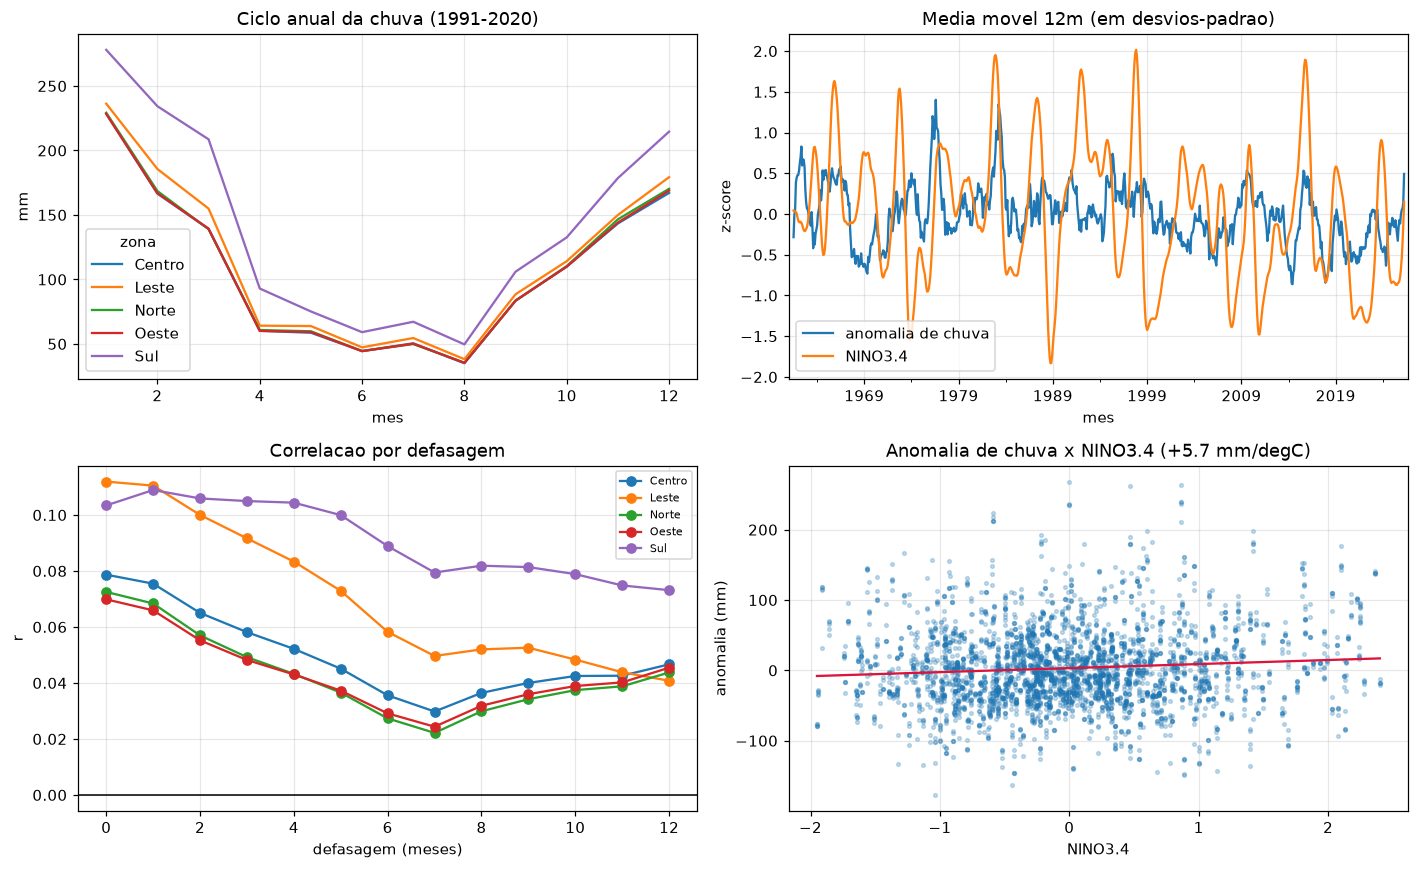

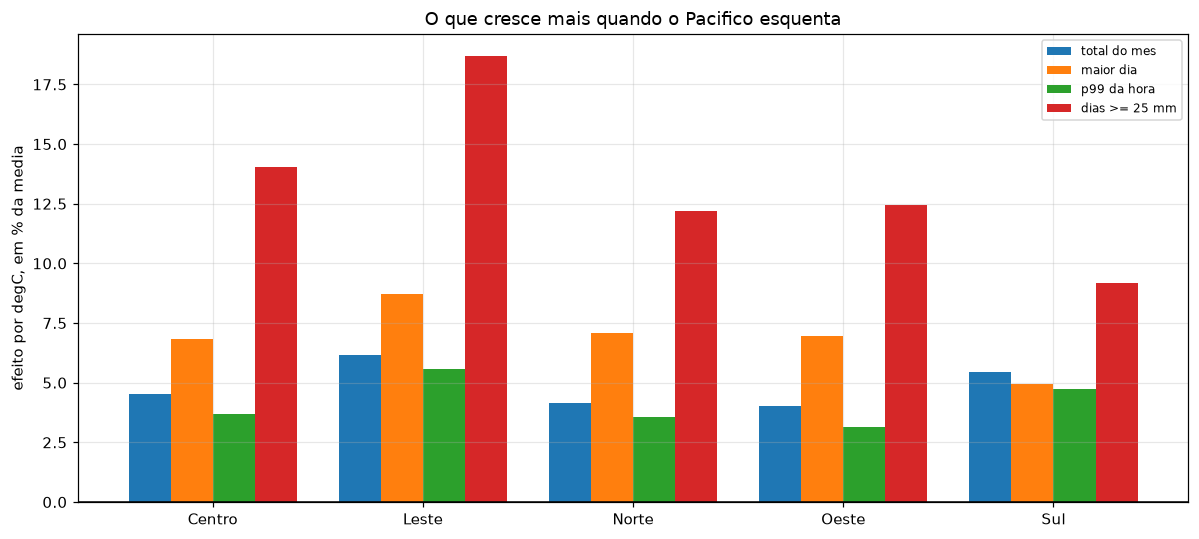

In [14]:
fig, eixos = plt.subplots(2, 2, figsize=(13, 8))

# 1) ciclo anual
clima.pivot(index="mes_num", columns="zona", values="clima_chuva_mm").plot(ax=eixos[0, 0])
eixos[0, 0].set_title("Ciclo anual da chuva (1991-2020)")
eixos[0, 0].set_xlabel("mes")
eixos[0, 0].set_ylabel("mm")

# 2) series padronizadas
mensal_pool = painel.groupby("mes").agg(anomalia=("anomalia_mm", "mean"), nino=("nino34", "first"))
padronizado = (mensal_pool - mensal_pool.mean()) / mensal_pool.std()
padronizado.rename(columns={"anomalia": "anomalia de chuva", "nino": "NINO3.4"}) \
    .rolling(12, center=True).mean().plot(ax=eixos[0, 1])
eixos[0, 1].set_title("Media movel 12m (em desvios-padrao)")
eixos[0, 1].set_ylabel("z-score")

# 3) correlacao por defasagem
for zona, g in correlacoes.groupby("zona"):
    eixos[1, 0].plot(g["lag_meses"], g["r"], marker="o", label=zona)
eixos[1, 0].axhline(0, color="black", linewidth=1)
eixos[1, 0].set_title("Correlacao por defasagem")
eixos[1, 0].set_xlabel("defasagem (meses)")
eixos[1, 0].set_ylabel("r")
eixos[1, 0].legend(fontsize=7)

# 4) dispersao
eixos[1, 1].scatter(painel["nino34"], painel["anomalia_mm"], s=6, alpha=0.25)
m, b = np.polyfit(painel["nino34"], painel["anomalia_mm"], 1)
x = np.linspace(painel["nino34"].min(), painel["nino34"].max(), 50)
eixos[1, 1].plot(x, m * x + b, color="crimson")
eixos[1, 1].set_title(f"Anomalia de chuva x NINO3.4 ({m:+.1f} mm/degC)")
eixos[1, 1].set_xlabel("NINO3.4")
eixos[1, 1].set_ylabel("anomalia (mm)")

plt.tight_layout()
plt.savefig(SAIDAS / "enso_chuva_paineis.png", dpi=140)
plt.show()

# --- efeito relativo: volume x intensidade ---
fig, ax = plt.subplots(figsize=(11, 5))
ordem_zonas = sorted(efeitos["zona"])
largura = 0.2
metricas_plot = [("chuva_mm", "total do mes"), ("max_dia_mm", "maior dia"),
                 ("p99_hora_mm", "p99 da hora"), ("dias_ge_25", "dias >= 25 mm")]
for i, (metrica, rotulo) in enumerate(metricas_plot):
    valores = efeitos.set_index("zona").loc[ordem_zonas, f"{metrica}_pct"]
    pos = np.arange(len(ordem_zonas)) + (i - 1.5) * largura
    ax.bar(pos, valores, largura, label=rotulo)

ax.axhline(0, color="black", linewidth=1)
ax.set_xticks(np.arange(len(ordem_zonas)), ordem_zonas)
ax.set_ylabel("efeito por degC, em % da media")
ax.set_title("O que cresce mais quando o Pacifico esquenta")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(SAIDAS / "enso_chuva_intensidade.png", dpi=140)
plt.show()

## 12. Exportacao

In [15]:
painel.drop(columns=[c for c in painel.columns if c.startswith("clima_")], errors="ignore") \
    .to_csv(SAIDAS / "enso_chuva_mensal.csv", index=False, encoding="utf-8-sig",
            sep=";", decimal=",")
correlacoes.to_csv(SAIDAS / "enso_chuva_correlacoes.csv", index=False,
                   encoding="utf-8-sig", sep=";", decimal=",")
por_zona.to_csv(SAIDAS / "enso_chuva_regressao_zona.csv", index=False,
                encoding="utf-8-sig", sep=";", decimal=",")
efeitos.to_csv(SAIDAS / "enso_chuva_intensidade.csv", index=False,
               encoding="utf-8-sig", sep=";", decimal=",")
comparacao.to_csv(SAIDAS / "enso_chuva_concentracao.csv", index=False,
                  encoding="utf-8-sig", sep=";", decimal=",")
cenario.to_csv(SAIDAS / "enso_chuva_cenario_2027.csv", index=False,
               encoding="utf-8-sig", sep=";", decimal=",")
dados_2026.to_csv(SAIDAS / "enso_chuva_2026.csv", index=False,
                  encoding="utf-8-sig", sep=";", decimal=",")

print("Arquivos gerados em", SAIDAS)
for arquivo in sorted(SAIDAS.glob("enso_chuva*")):
    print(f"  {arquivo.name}")

Arquivos gerados em C:\TI\Projetos Univesp\projeto-climaSP\Notebookes\saidas
  enso_chuva_2026.csv
  enso_chuva_cenario_2027.csv
  enso_chuva_concentracao.csv
  enso_chuva_correlacoes.csv
  enso_chuva_intensidade.csv
  enso_chuva_intensidade.png
  enso_chuva_mensal.csv
  enso_chuva_paineis.png
  enso_chuva_regressao_zona.csv
  enso_chuva_serie.png


## 13. Persistencia no banco

Publica a camada de chuva no Postgres local e no Supabase, com o mesmo padrao
do `nooa.ipynb`: coluna `index` comecando em 1, `if_exists="replace"` e copia
da tabela local para a nuvem.

| Tabela | Conteudo |
|---|---|
| `df_chuva_mensal` | serie mensal por zona, 1961-2026 |
| `df_chuva_intensidade` | efeito por grau em % da media, por zona e metrica |
| `df_chuva_concentracao` | bootstrap total x maior dia, com IC95 |
| `df_chuva_cenario` | cenario de jan e fev de 2027 |
| `df_chuva_2026` | caso 2026, mes a mes e por zona |


In [16]:
# ============================================================
# 13. Persistencia no Postgres local e no Supabase
# ============================================================
import os

from sqlalchemy import create_engine, text

engine_local = create_engine(
    os.environ["LOCAL_DB_URL"], connect_args={"connect_timeout": 15}
)


def salvar_local(df, nome, index_label="index"):
    df = df.copy()
    df.index = range(1, len(df) + 1)
    df.to_sql(
        name=nome,
        con=engine_local,
        if_exists="replace",
        index=True,
        index_label=index_label,
        method="multi",
        chunksize=500,
    )
    print(f"local   {nome:<24} {len(df):>5} linhas")


def publicar(nome):
    df = pd.read_sql(text(f'SELECT * FROM "{nome}"'), engine_local)
    df.to_sql(
        name=nome,
        con=engine,
        if_exists="replace",
        index=False,
        method="multi",
        chunksize=500,
    )
    n = pd.read_sql(text(f'SELECT count(*) AS n FROM "{nome}"'), engine)["n"][0]
    print(f"nuvem   {nome:<24} local={len(df):>5}  supabase={n:>5}")


# Mesmo padrao do nooa: data como timestamp e contagens em bigint, para o
# local e a nuvem ficarem com o mesmo schema.
mensal_db = (
    painel.drop(columns=[c for c in painel.columns if c.startswith("clima_")], errors="ignore")
    .assign(mes=lambda d: pd.to_datetime(d["mes"]))
    .astype({"ano": "int64", "mes_num": "int64"})
)
caso_2026_db = (
    dados_2026.assign(mes=lambda d: pd.to_datetime(d["mes"]))
    .astype({"ano": "int64", "mes_num": "int64"})
)
cenario_db = cenario.assign(mes=lambda d: pd.to_datetime(d["mes"], format="%m/%Y"))

TABELAS_CHUVA = {
    "df_chuva_mensal": mensal_db,
    "df_chuva_intensidade": efeitos,
    "df_chuva_concentracao": comparacao,
    "df_chuva_cenario": cenario_db,
    "df_chuva_2026": caso_2026_db,
}

for nome, tabela in TABELAS_CHUVA.items():
    salvar_local(tabela, nome)

print()
for nome in TABELAS_CHUVA:
    publicar(nome)


local   df_chuva_mensal           3945 linhas
local   df_chuva_intensidade         5 linhas
local   df_chuva_concentracao        5 linhas
local   df_chuva_cenario            10 linhas
local   df_chuva_2026               45 linhas

nuvem   df_chuva_mensal          local= 3945  supabase= 3945
nuvem   df_chuva_intensidade     local=    5  supabase=    5
nuvem   df_chuva_concentracao    local=    5  supabase=    5
nuvem   df_chuva_cenario         local=   10  supabase=   10
nuvem   df_chuva_2026            local=   45  supabase=   45


In [17]:
print("RESUMO")
print("=" * 66)
for _, linha in resumo_lag.iterrows():
    print(f"{linha['zona']:<7} r = {linha['r']:+.3f} | p_efetivo = {linha['p_efetivo']:.3f} "
          f"| n_ef = {linha['n_efetivo']}")
print()
print(f"Total, com efeito fixo de mes e zona: {coef_total:+.2f} mm/degC "
      f"(IC95% {ic[0]:+.2f} a {ic[1]:+.2f})")
print()
print("Efeito por degC em % da media:")
print(efeitos.set_index("zona")[["chuva_mm_pct", "max_dia_mm_pct", "p99_hora_mm_pct"]]
      .rename(columns={"chuva_mm_pct": "total", "max_dia_mm_pct": "maior_dia",
                       "p99_hora_mm_pct": "p99_hora"})
      .round(1).to_string())
print()
print(resultado.round(1).to_string(index=False))

RESUMO
Centro  r = +0.079 | p_efetivo = 0.039 | n_ef = 688
Leste   r = +0.112 | p_efetivo = 0.004 | n_ef = 663
Norte   r = +0.073 | p_efetivo = 0.053 | n_ef = 710
Oeste   r = +0.070 | p_efetivo = 0.065 | n_ef = 699
Sul     r = +0.103 | p_efetivo = 0.014 | n_ef = 564

Total, com efeito fixo de mes e zona: +5.84 mm/degC (IC95% +0.97 a +10.71)

Efeito por degC em % da media:
        total  maior_dia  p99_hora
zona                              
Centro    4.5        6.8       3.7
Leste     6.2        8.7       5.6
Norte     4.2        7.1       3.6
Oeste     4.0        7.0       3.2
Sul       5.4        5.0       4.7

      alvo  rmse_modelo  rmse_climatologia  ganho_pct
  chuva_mm         52.7               97.6       46.0
max_dia_mm         13.9               15.5       10.3


## Leitura dos resultados

### O sinal existe, é fraco, e mais forte no Leste e no Sul

A correlação entre a anomalia de chuva e o NINO3.4 é positiva em todas as zonas,
mas baixa: `r` de +0,070 (Oeste) a +0,112 (Leste). Com correção para
autocorrelação, o p efetivo fica abaixo de 0,05 em Centro (0,039), Leste (0,004)
e Sul (0,014); Norte (0,053) e Oeste (0,065) ficam na fronteira.

Traduzindo em volume, o modelo com efeito fixo de mês e zona dá
**+5,84 mm por °C** (IC95% +0,97 a +10,71). O intervalo é largo porque o ENSO
explica pouco do mês de chuva — o resíduo de clima é grande. O que importa é que
o efeito não é zero.

### A pancada cresce mais que o volume — mas o teste é inconclusivo

O achado central do passo 7 é a diferença de inclinação entre as métricas:

| Métrica | Efeito por °C (% da média) |
|---|---|
| Total do mês | +4,0% a +6,2% |
| Maior dia do mês | +5,0% a +8,7% |
| p99 da hora | +3,2% a +5,6% |
| Dias ≥ 25 mm (fator Poisson) | 1,08 a 1,16 por °C |

O maior dia cresce de 2,4 a 3,0 pontos percentuais **mais** que o total em
quatro zonas, e menos no Sul (–0,5 p.p.). Só que o bootstrap do delta tem IC95
cruzando zero em todas as zonas (–5,4 a +7,6 p.p.). Ou seja: a direção é
consistente em quase todas as zonas, mas a amostra não permite afirmar que a
concentração aumenta. O que se pode afirmar com o p-valor do modelo é o efeito
sobre o maior dia em si: significativo em Centro (0,015), Leste (0,002), Norte
(0,011) e Oeste (0,013), e na fronteira no Sul (0,077).

Conclusão honesta: **a chuva de São Paulo responde ao aquecimento do Pacífico
tanto em volume quanto em intensidade, e a intensidade parece responder mais.
Mas o teste de concentração não fecha com os dados disponíveis.**

### O modelo bate a climatologia no total, pouco no maior dia

Validação temporal (treino 1961–2009, teste 2010–2026):

| Alvo | RMSE do modelo | RMSE da climatologia | Ganho |
|---|---:|---:|---:|
| Chuva do mês (mm) | 52,7 | 97,6 | 46,0% |
| Maior dia do mês (mm) | 13,9 | 15,5 | 10,3% |

O modelo agrega muito valor no acumulado e pouco no extremo diário. Isso é
esperado: evento extremo é ruidoso e o NINO3.4 é um preditor de escala mensal,
não de dia.

### Cenário de jan e fev de 2027

Com o NINO3.4 projetado em 2,314 (DJF) e 1,982 (JFM):

- chuva esperada entre **175,7 mm** (Oeste, fev) e **296,1 mm** (Sul, jan);
- desvio de **+8,8 a +18,1 mm** sobre a climatologia, ou +4,5% a +7,8%;
- maior dia esperado de 33,1 mm (Centro/Oeste, fev) a 43,2 mm (Leste, jan).

O desvio projetado cabe inteiro dentro do RMSE de 54 mm. A leitura correta não é
"vai chover 18 mm a mais", e sim **"a tendência é de chuva acima da média, com
sinal fraco perto do erro do modelo"**.

### Setembro de 2026

Setembro de 2026 é o setembro mais quente no Pacífico equatorial da série
(2,10 °C, à frente de 1997 com 2,07 °C). A chuva de setembro de 2026 ficou
+167% a +177% acima da média nas cinco zonas, e o maior dia +60% a +85%. É um caso
único, não uma amostra — serve de ilustração, não de prova.

### Ressalvas

- A chuva é ERA5/ERA5-Land, não pluviômetro. A célula de 0,25° não distingue
  Centro, Norte e Oeste antes de 2017; só Leste e Sul têm célula própria em todo
  o período.
- O NINO3.4 é trimestral (média móvel de 3 meses); a chuva é mensal. A defasagem
  zero já embute essa suavização.
- O elo 4 (chuva forte que alaga) não é medido aqui: depende de drenagem,
  relevo e impermeabilização. O CEMADEN entra depois, no evento de 2026, com
  dados consolidados.
- As cinco tabelas desta análise foram publicadas no Postgres local e no
  Supabase: `df_chuva_mensal`, `df_chuva_intensidade`, `df_chuva_concentracao`,
  `df_chuva_cenario` e `df_chuva_2026`.
